# 10 · Survival analysis: how long does a fare last? (R)

When I find a fare I like, the real question is **how long I have before it
goes up**. Survival analysis is built for "time until something happens"
questions, including when some cases never reach the event in the
observation window (here, departure arrives first).

**Key takeaways**
1. **Almost every fare eventually rises 5%** (93–95% before departure). The
   question is how soon.
2. **A fare seen 60 days out typically lasts about 18 days** before rising 5%;
   from 30 days out, about 10 days; **from 21 days out, just 3**.
3. **Deadlines show up as cliffs.** Starting exactly 21 days out, **38% of
   fares rise at least 5% the very next day**, when the 21-day deadline
   passes.
4. **Far out, a drop usually comes first** (56% of the time from 60 days out);
   from 21 days out, a rise comes first 64% of the time.
5. **Expensive fares rise much more slowly** (hazard ratio 0.45 vs. cheap
   fares). A cheap fare is worth grabbing; an expensive one can wait.

In [1]:
suppressPackageStartupMessages({
  library(DBI); library(duckdb); library(data.table)
  library(survival); library(ggplot2); library(modelsummary)
})
options(repr.plot.width = 9, repr.plot.height = 4.2, repr.plot.res = 110, width = 120)

data_dir <- Sys.getenv("FLIGHT_DATA_DIR",
                       file.path(Sys.getenv("USERPROFILE"), "data", "flight-pricing"))
con <- dbConnect(duckdb(shared_home = FALSE))
q <- function(sql) as.data.table(dbGetQuery(con, sql))
cheapest <- file.path(data_dir, "processed", "cheapest_daily.parquet")

blue <- "#2a78d6"; orange <- "#eb6834"; aqua <- "#1baf7a"; yellow <- "#eda100"; muted <- "#52514e"
theme_set(theme_minimal(base_size = 11) + theme(
  plot.background = element_rect(fill = "#fcfcfb", colour = NA),
  panel.grid.minor = element_blank(),
  plot.title = element_text(face = "bold", hjust = 0, colour = "#0b0b0b"),
  axis.title = element_text(colour = muted), axis.text = element_text(colour = muted),
  legend.position = "bottom"))

## Setting it up as a survival problem

For each trip and starting point $s$ (60, 45, 30 or 21 days out), I start a
clock at the fare $P_s$ and follow the cheapest fare day by day:

- **Event "rise":** the first day the fare is at least 5% **above** $P_s$.
- **Event "drop":** the first day the fare is at least 5% **below** $P_s$.
- **Censored:** neither happens before the last day with a price
  (departure, or the end of data collection). I know the fare survived *at
  least* that long, but not what came after.

Censoring is why I can't just average the "days until a rise". Trips that
never rose would either be dropped (biasing the answer toward short times)
or counted as rising at departure (also wrong). Survival methods use the
partial information correctly.

In [2]:
starts <- c(60, 45, 30, 21)
spells <- rbindlist(lapply(starts, function(s) q(sprintf("
  WITH st AS (
    SELECT origin, dest, flightDate, fare AS p0, isNonStop, airlines
    FROM '%1$s'
    WHERE days_ahead = %2$d
      AND flightDate - INTERVAL %2$d DAY >= DATE '2022-04-16'
      AND flightDate <= DATE '2022-10-06'),
  later AS (
    SELECT c.origin, c.dest, c.flightDate, c.days_ahead, c.fare, st.p0
    FROM '%1$s' c JOIN st USING (origin, dest, flightDate)
    WHERE c.days_ahead < %2$d)
  SELECT st.origin, st.dest, st.origin || '-' || st.dest AS route, st.flightDate, st.p0,
         st.isNonStop::INT AS nonstop,
         (split_part(st.airlines, '||', 1) IN ('Spirit Airlines', 'Frontier Airlines'))::INT AS budget,
         %2$d AS start,
         %2$d - max(l.days_ahead) FILTER (WHERE l.fare >= 1.05 * l.p0) AS t_rise,
         %2$d - max(l.days_ahead) FILTER (WHERE l.fare <= 0.95 * l.p0) AS t_drop,
         %2$d - min(l.days_ahead) AS t_last
  FROM st JOIN later l USING (origin, dest, flightDate)
  GROUP BY ALL", cheapest, s))))

# Fare level at the start: relative to the route's median cheapest fare
route_med <- q(sprintf("SELECT origin || '-' || dest AS route, median(fare) AS med FROM '%s' GROUP BY 1", cheapest))
spells <- merge(spells, route_med, by = "route")
spells[, fare_level := cut(log(p0 / med), c(-Inf, -0.15, 0.15, Inf),
                           labels = c("cheap", "normal", "expensive"))]
spells[, flight_dow := factor(weekdays(as.Date(flightDate)),
                              c("Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"))]

# Rise-only analysis: time to first rise, censored at the last observed day
spells[, `:=`(time_rise = fifelse(is.na(t_rise), t_last, t_rise), rose = as.integer(!is.na(t_rise)))]
# Competing risks: whichever 5% move comes first
spells[, first := fifelse(!is.na(t_rise) & (is.na(t_drop) | t_rise <= t_drop), "rise",
                  fifelse(!is.na(t_drop), "drop", "censored"))]
spells[, time_first := fifelse(first == "rise", t_rise, fifelse(first == "drop", t_drop, t_last))]
spells[, first := factor(first, c("censored", "rise", "drop"))]

spells[, .(trips = .N, rose = mean(rose), first_rise = mean(first == "rise"),
           first_drop = mean(first == "drop"), censored = mean(first == "censored")), by = start]

start,trips,rose,first_rise,first_drop,censored
<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>
60,15333,0.9350421,0.4396400,0.5603600,0.0000000000
45,24565,0.9522898,0.5242011,0.4757989,0.0000000000
30,29505,0.9448568,0.5661752,0.4335197,0.0003050330
21,32989,0.9447088,0.6430628,0.3564522,0.0004850102


## 1. How long does a fare survive? (Kaplan–Meier)

The **Kaplan–Meier estimator** gives the probability that the fare hasn't
yet risen 5% after $k$ days:

$$\hat S(k) = \prod_{j \le k}\left(1 - \frac{d_j}{n_j}\right)$$

where $n_j$ is the number of trips still "at risk" (not yet risen, not yet
censored) on day $j$, and $d_j$ is how many rose that day. Censored trips
count in $n_j$ for as long as they're observed, then leave quietly.

,records,events,median
start=21,32989,31165,3
start=30,29505,27878,10
start=45,24565,23393,11
start=60,15333,14337,18


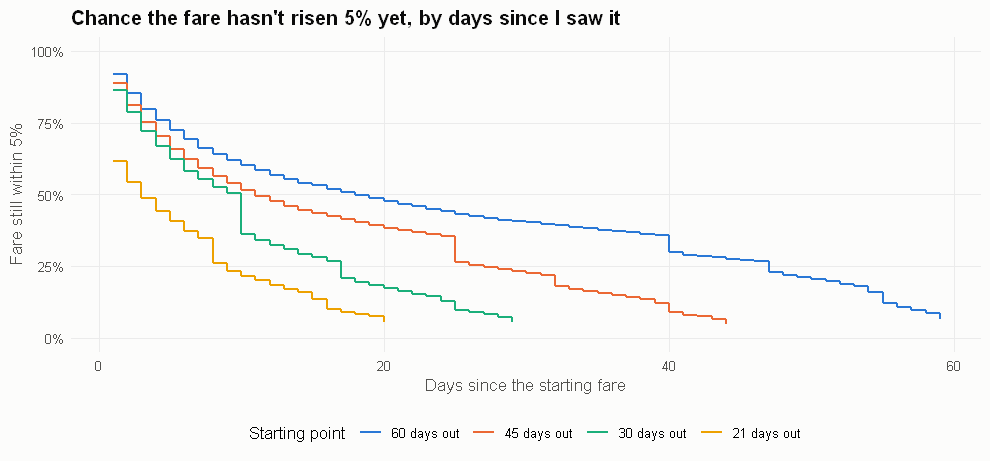

In [3]:
km_start <- survfit(Surv(time_rise, rose) ~ start, data = spells)
km_dt <- as.data.table(broom_like <- data.frame(time = km_start$time, surv = km_start$surv,
  strata = rep(names(km_start$strata), km_start$strata)))
km_dt[, start := factor(sub("start=", "", strata), levels = as.character(starts),
                        labels = paste(starts, "days out"))]
ggplot(km_dt, aes(time, surv, colour = start)) +
  geom_step(linewidth = 0.9) +
  scale_colour_manual(values = c(blue, orange, aqua, yellow), name = "Starting point") +
  scale_y_continuous(labels = scales::percent, limits = c(0, 1)) +
  labs(title = "Chance the fare hasn't risen 5% yet, by days since I saw it",
       x = "Days since the starting fare", y = "Fare still within 5%")

summary(km_start, times = c(3, 7, 14))$table[, c("records", "events", "median")]

In [4]:
s_tab <- summary(km_start, times = c(3, 7, 14))
dcast(data.table(start = sub("start=", "", as.character(s_tab$strata)), days = s_tab$time,
                 still_ok = round(s_tab$surv, 3)),
      start ~ paste0("after ", days, " days"), value.var = "still_ok")[order(-as.integer(start))]

start,after 14 days,after 3 days,after 7 days
<chr>,<dbl>,<dbl>,<dbl>
60,0.541,0.798,0.662
45,0.446,0.752,0.590
30,0.292,0.721,0.553
21,0.158,0.486,0.346


Reading the curves: after $k$ days, what share of starting fares are still
within 5% of where they began?

| Starting point | Median days until a 5% rise | Still within 5% after 7 days | after 14 days |
|---|---|---|---|
| 60 days out | 18 | 66% | 54% |
| 45 days out | 11 | 59% | 45% |
| 30 days out | 10 | 55% | 29% |
| 21 days out | **3** | 35% | 16% |

**The cliffs are the deadlines.** Each curve drops sharply on the day a
deadline passes: from 60 days out at day 40 (20 days before departure) and
day 47 (13 days before); from 30 days out at days 10 and 17; from 21 days out
on day 1. This is the same deadline effect as notebook 03, now seen as "how
long does my fare last?"

**Practical reading:** from 21 days out, a fare I like has about a 1-in-3
chance of rising 5% by tomorrow. Far out, I usually have a couple of weeks.

### By fare level, starting 30 days out

Call:
survdiff(formula = Surv(time_rise, rose) ~ fare_level, data = spells[start == 
    30])

                         N Observed Expected (O-E)^2/E (O-E)^2/V
fare_level=cheap     11655    11618     9231       617      1094
fare_level=normal     9575     9438     8302       155       258
fare_level=expensive  8275     6822    10345      1200      2387

 Chisq= 2469  on 2 degrees of freedom, p= <2e-16 

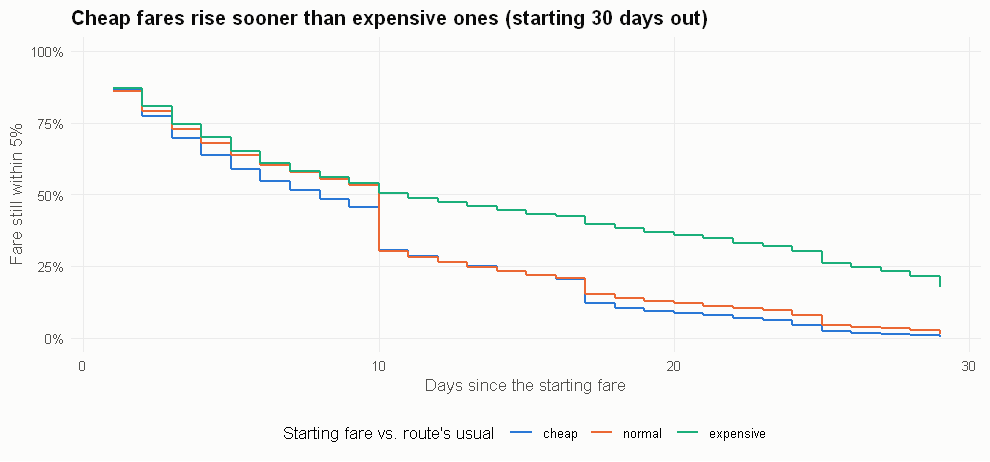

In [5]:
km_level <- survfit(Surv(time_rise, rose) ~ fare_level, data = spells[start == 30])
lv <- data.table(time = km_level$time, surv = km_level$surv,
                 strata = rep(names(km_level$strata), km_level$strata))
lv[, level := factor(sub("fare_level=", "", strata), c("cheap", "normal", "expensive"))]
ggplot(lv, aes(time, surv, colour = level)) +
  geom_step(linewidth = 0.9) +
  scale_colour_manual(values = c(blue, orange, aqua), name = "Starting fare vs. route's usual") +
  scale_y_continuous(labels = scales::percent, limits = c(0, 1)) +
  labs(title = "Cheap fares rise sooner than expensive ones (starting 30 days out)",
       x = "Days since the starting fare", y = "Fare still within 5%")
survdiff(Surv(time_rise, rose) ~ fare_level, data = spells[start == 30])

**Cheap fares rise sooner.** Starting 30 days out, fares that begin more
than 15% below the route's usual level rise faster than normal ones, and
expensive fares rise slowest. They're already high, so a further 5% rise is
less likely than a fall back.

The **log-rank test** compares the curves: it checks whether the observed
number of rises in each group differs from what you'd expect if all groups
shared one survival curve. With χ² = 2,469 on 2 degrees of freedom, the
difference is far beyond chance.

This is the survival-analysis version of what the models learned: **buy cheap
fares, wait on expensive ones.**

## 2. Which comes first, a rise or a drop? (competing risks)

A fare can move either way, and the first big move ends the question of
"should I have waited?". With two competing events, the right summary is the
**cumulative incidence function**: the probability that a *rise* (or a
*drop*) has happened **first** by day $k$. It's estimated with the
Aalen–Johansen method, which handles censoring the same way Kaplan–Meier
does.

start,rise_first,drop_first,neither
<chr>,<dbl>,<dbl>,<dbl>
21,0.643,0.356,0
30,0.566,0.434,0
45,0.524,0.476,0
60,0.440,0.560,0


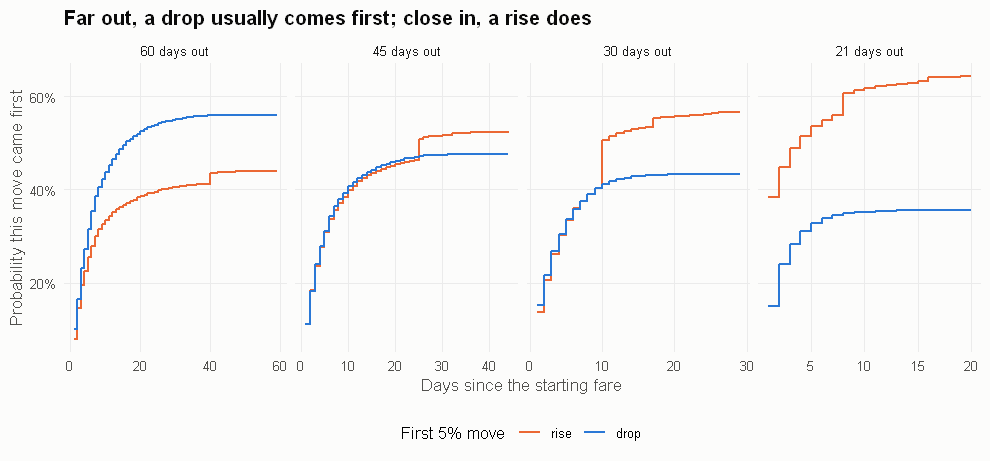

In [6]:
ci <- survfit(Surv(time_first, first) ~ start, data = spells)
ci_dt <- rbindlist(lapply(seq_along(ci$strata), function(k) {
  rows <- (c(0, cumsum(ci$strata))[k] + 1):cumsum(ci$strata)[k]
  data.table(start = sub("start=", "", names(ci$strata)[k]), time = ci$time[rows],
             rise = ci$pstate[rows, which(ci$states == "rise")],
             drop = ci$pstate[rows, which(ci$states == "drop")])
}))
ci_long <- melt(ci_dt, id.vars = c("start", "time"), variable.name = "event", value.name = "prob")
ci_long[, start := factor(start, levels = as.character(starts), labels = paste(starts, "days out"))]
ggplot(ci_long, aes(time, prob, colour = event)) +
  geom_step(linewidth = 0.9) + facet_wrap(~start, nrow = 1, scales = "free_x") +
  scale_colour_manual(values = c(rise = orange, drop = blue), name = "First 5% move") +
  scale_y_continuous(labels = scales::percent) +
  labs(title = "Far out, a drop usually comes first; close in, a rise does",
       x = "Days since the starting fare", y = "Probability this move came first")

ci_dt[, .SD[.N], by = start][, .(start, rise_first = round(rise, 3), drop_first = round(drop, 3),
                                neither = round(1 - rise - drop, 3))]

The curves show which 5% move happens **first**:

| Starting point | Rise first | Drop first |
|---|---|---|
| 60 days out | 44% | **56%** |
| 45 days out | 52% | 48% |
| 30 days out | 57% | 43% |
| 21 days out | **64%** | 36% |

Far from departure, the next big move is more likely down than up, so
waiting is favored. By 21 days out, the odds have flipped: the next big move is
most likely up. That flip is the whole buy-or-wait problem in one table.

Why not just use Kaplan–Meier for each event separately? Because treating a
drop as "censoring" for the rise analysis would assume the rise could still
have come first, which overstates the chance of each event. The cumulative
incidence functions add up correctly: rise + drop + neither = 100%.

## 3. What makes a rise come sooner? (Cox model)

The **Cox proportional-hazards model** describes the daily risk of a rise
(the *hazard*) as a baseline risk times a multiplier from the trip's
characteristics:

$$h(k \mid x) = h_0(k)\, e^{\beta^\top x}$$

$e^{\beta}$ is a **hazard ratio**: 1.3 means a rise comes 30% faster on any
given day; 0.7 means 30% slower. The baseline $h_0(k)$ is left completely
unspecified, which is what makes the model flexible. Standard errors are
clustered by route, as everywhere else in the project.

In [7]:
cox <- coxph(Surv(time_rise, rose) ~ fare_level + factor(start) + nonstop + budget + flight_dow,
             data = spells, cluster = route)
hr <- as.data.table(summary(cox)$conf.int, keep.rownames = "term")[, .(term, hazard_ratio = round(`exp(coef)`, 3),
      ci_low = round(`lower .95`, 3), ci_high = round(`upper .95`, 3))]
hr[, term := gsub("fare_level|factor\\(start\\)|flight_dow", "", term)]
hr

term,hazard_ratio,ci_low,ci_high
<chr>,<dbl>,<dbl>,<dbl>
normal,0.847,0.817,0.878
expensive,0.454,0.432,0.478
30,0.554,0.529,0.579
45,0.350,0.322,0.379
60,0.186,0.166,0.208
nonstop,0.995,0.960,1.030
budget,0.961,0.919,1.005
Tuesday,0.845,0.822,0.869
Wednesday,0.856,0.831,0.882


Hazard ratios (a value below 1 means a rise comes more slowly):

- **Fare level:** compared with cheap fares, normal fares rise 15% more slowly
  and **expensive fares 55% more slowly** (HR 0.45).
- **Starting point:** compared with 21 days out, a rise comes 45% more slowly
  from 30 days out and **81% more slowly from 60 days out** (HR 0.19).
- **Flight day:** Tuesday and Wednesday flights rise about 15% more slowly
  than Monday flights, and Sunday flights slightly faster. That echoes
  notebook 03's flight-day effect.
- **Nonstop and budget-carrier status:** no clear effect (the intervals
  include 1).

## Checking the proportional-hazards assumption

The Cox model assumes each multiplier stays the same over time. The
Grambsch–Therneau test checks that using scaled Schoenfeld residuals. A small
p-value means the effect changes with time.

In [8]:
cox.zph(cox)

               chisq df       p
fare_level     421.9  2 < 2e-16
factor(start) 4073.0  3 < 2e-16
nonstop        539.4  1 < 2e-16
budget         270.3  1 < 2e-16
flight_dow      49.2  6 6.9e-09
GLOBAL        5451.6 13 < 2e-16

A common fix when one variable's effect clearly changes over time is to
**stratify** on it: give each starting point its own baseline hazard
$h_{0,s}(k)$, so its effect no longer has to be proportional. If the other
hazard ratios barely move, they're robust.

In [9]:
cox_strat <- coxph(Surv(time_rise, rose) ~ fare_level + nonstop + budget + flight_dow + strata(start),
                   data = spells, cluster = route)
compare <- merge(hr, as.data.table(summary(cox_strat)$conf.int, keep.rownames = "term")[
  , .(term = gsub("fare_level|flight_dow", "", term), stratified_hr = round(`exp(coef)`, 3))],
  by = "term", all.x = TRUE)
compare[!grepl("^[0-9]", term)]

term,hazard_ratio,ci_low,ci_high,stratified_hr
<chr>,<dbl>,<dbl>,<dbl>,<dbl>
Friday,0.952,0.922,0.983,0.962
Saturday,0.874,0.849,0.901,0.884
Sunday,1.043,1.013,1.073,1.045
Thursday,0.925,0.893,0.959,0.933
Tuesday,0.845,0.822,0.869,0.841
Wednesday,0.856,0.831,0.882,0.858
budget,0.961,0.919,1.005,0.965
expensive,0.454,0.432,0.478,0.423
nonstop,0.995,0.960,1.030,1.012


**The test rejects proportional hazards for every variable.** That's
expected for two reasons:

1. **The deadlines make the hazard spike on specific days**, and those days
   fall at different times since the start for different starting points. So
   the starting point's effect can't be one constant multiplier.
2. **With about 100,000 trips, the test detects even tiny departures** from
   proportionality.

The stratified model handles point 1 by giving each starting point its own
baseline. The fare-level and flight-day hazard ratios barely change, so those
conclusions are robust. The hazard ratios are best read as **average
effects over the waiting period**.

## What this means for buying

- **Far out (45–60 days):** a fare usually lasts a couple of weeks, and the
  next big move is more often down. Waiting is reasonable, especially on an
  expensive fare.
- **Near a deadline:** the clock runs out fast. From 21 days out, a third of
  fares rise 5% by the next day.
- **Cheap fares rise soonest**, so a fare well below the route's usual price
  is the one not to sit on.

These are the same patterns the reinforcement-learning policy discovered in
notebook 08, measured here directly as "how long do I have?"